
## Problem Statement

Identify relationships between different product categories and their features, then use these relationships along with user preferences and review data to recommend relevant products across categories.



# 1. Data Provenance and Data Generation Process

## 1.1 Data Source

The primary data source for this project is the **Amazon Reviews 2023 dataset**, collected and released by the McAuley Lab at the University of California, San Diego (UCSD).

The dataset provides large-scale, multi-category information about Amazon products and user interactions. It contains three major types of information:

- **User Reviews:** Numerical ratings, review titles, review texts, helpfulness votes, timestamps, and other interaction-related attributes.
- **Product Metadata:** Product titles, descriptions, prices, brands, categories, images, and other product characteristics.
- **Product Relationships:** Relationships between products, including also-bought and bought-together associations.

According to the dataset documentation, the complete collection contains approximately 571.54 million reviews, 54.51 million users, and 48.19 million products across 33 categories.

## 1.2 Data Collection Method

The dataset was collected from Amazon's publicly available product review and product information pages through a web-based data collection process conducted by the dataset authors.

The collected information was subsequently processed and organized into structured JSONL files. Each line represents an individual JSON record, allowing the data to be processed independently and efficiently.

For this project, two main groups of files are used:

1. **Review files (`*.jsonl`):** Contain user-generated reviews and rating information, including user identifiers, product identifiers, timestamps, and review text.
2. **Metadata files (`meta_*.jsonl`):** Contain product-level information, such as titles, descriptions, categories, brands, prices, and product relationships.

The review and metadata records are linked primarily through product identifiers (`parent_asin`), while user identifiers (`user_id`) allow interactions to be associated with individual users.

## 1.3 Time Range

The original Amazon Reviews 2023 dataset covers interactions from **May 1996 to September 2023**.

The exact temporal coverage of the working dataset depends on the selected categories and available records. Review timestamps are used to establish the temporal distribution of user interactions.

An important distinction is that review timestamps represent the time when a review interaction was recorded, not necessarily the actual purchase date.

Product metadata, on the other hand, generally represents product information collected during the dataset collection process and should not be interpreted as a complete historical record of product attributes.

## 1.4 Unit of Observation

The unit of observation depends on the type of data being analyzed.

**A. Review-Level Observations**

For the review dataset, one observation corresponds to one individual review or rating record submitted by a user for a product.

The main identifiers are:

- `user_id`: Identifies the reviewer.
- `parent_asin`: Identifies the product entity.
- `asin`: Identifies the specific product identifier when available.
- `rating`: Represents the user's numerical evaluation.
- `timestamp`: Represents the time of the review.
- `text`: Contains the review content.

A review-level observation can therefore be interpreted as a user–product interaction.

**B. Product-Level Observations**

For the metadata dataset, one observation corresponds to one product record.

Each record describes product characteristics, such as its title, description, brand, category, price, and related products.

**C. User-Level Observations**

For user behavior analysis, multiple review-level observations can be grouped by `user_id` to construct user profiles and interaction histories.

These aggregated observations can be used to identify preferences, category interests, and cross-category relationships.

## 1.5 Data Generation Process: Observational or Controlled?

The Amazon Reviews 2023 dataset is fundamentally **observational data**, rather than data generated through a controlled experimental process.

The dataset records naturally occurring user interactions and product information on an e-commerce platform. Users independently choose which products to review, what ratings to assign, and what information to include in their review texts.

The dataset authors collected and organized these existing records; they did not randomly assign users to products, manipulate product exposure, or control purchasing decisions through an experimental design.

Consequently, the observed interactions reflect real-world user behavior, but they are not necessarily representative of all users or all purchasing decisions.

It is also important to distinguish between different interaction signals:

- A review or rating provides evidence of an observed user–product interaction.
- The `verified_purchase` attribute indicates whether a review is associated with a verified purchase.
- Product relationship fields, such as `also_bought` and `bought_together`, describe product associations and should not automatically be interpreted as verified individual purchase histories.

Therefore, the dataset provides useful behavioral signals, but it does not constitute a complete transaction-level purchase log.

## 1.6 Main Data Limitations

Several limitations should be considered when analyzing the dataset and developing recommendation models:

1. **Selection Bias:** Users who submit reviews may have different characteristics from users who purchase products without reviewing them.

2. **Missing Information:** Some products have incomplete metadata, including missing descriptions, prices, images, or other attributes.

3. **Interaction Sparsity:** Most users interact with only a small subset of the available products, resulting in sparse user–item interaction data.

4. **Temporal Limitations:** The dataset ends in September 2023. Consequently, it does not capture subsequent user behavior, product changes, or emerging preferences.

5. **Purchase Information Limitations:** Reviews are not equivalent to complete purchase records. The dataset does not provide a comprehensive history of orders, quantities, transaction values, or all purchases made by each user.

6. **Non-Random Interactions:** Product exposure and user choices are not randomly assigned. Therefore, observed relationships between users and products cannot automatically be interpreted as causal relationships.

7. **Metadata Consistency:** Product attributes and available fields may differ across categories, requiring data validation and consistent preprocessing before cross-category analysis.

8. **Review Reliability:** Ratings and review texts represent subjective user opinions and may contain biased, misleading, duplicated, or otherwise unreliable information.





becuase or question or objective is to predict the feture action of the user if the text of the user contain somthing like the (I bought this item with that one) this will or even given the answer of the model. and the bought also column in the data is data leakage
(even though for all of the data are missing )

importing library

In [1]:
from multiprocessing import Pool
from pathlib import Path
from typing import TypedDict
import pandas as pd
import matplotlib as plt
import json
import re
from IPython.display import display


## Dataset Structure and Selected Categories

The main connection between the review and metadata files is the `parent_asin` identifier, which can be used to join the two datasets. We can also use the `asin` field to identify and distinguish different product variations within the same product group.

This project will initially focus on the following categories:

- CDs and Vinyl
- Cell Phones and Accessories
- Digital Music
- Electronics
- Gift Cards
- Magazine Subscriptions
- Movies and TV
- Musical Instruments
- Software
- Subscription Boxes
- Toys and Games
- Video Games

Some categories, particularly subscription-related ones, may be changed or removed in later phases of the project.

The reason for selecting these categories is that they have different levels of influence and connections with one another. Some categories may have strong relationships, while others may have weaker or less obvious connections. This variety will help us discover meaningful relationships between categories and build a cross-category recommendation system.

---

> **⚠️ IMPORTANT: DATA REPORT GENERATION**
>
> The code below generates a `data_report.json` file containing the results of the initial data analysis.
>
> **This process is computationally intensive and may take approximately 30 minutes to complete.**
>
> **Run this code only once to generate the JSON file.** Do not rerun it unnecessarily, as the process takes a considerable amount of time. Once the file has been generated successfully, you can reuse it in the following steps without running the code again.


In [7]:


try:
    import orjson
    loads = orjson.loads
except ImportError:
    loads = json.loads

PARENT_DIR = Path('/media/ghaedi/Data/amazon')
REPORT_PATH = Path('data_report.json')
PROGRESS_EVERY = 1_000_000

# Word count means whitespace-separated tokens, not linguistic tokenization.
LENGTH_BINS = {
    'very_short': {'min_words': 1, 'max_words': 3},
    'short': {'min_words': 4, 'max_words': 20},
    'medium': {'min_words': 21, 'max_words': 100},
    'long': {'min_words': 101, 'max_words': None},
}

CONTROL_RE = re.compile(r'[\x00-\x08\x0b\x0c\x0e-\x1f\x7f-\x9f]')
SURROGATE_RE = re.compile(r'[\ud800-\udfff]')
FLAG_NAMES = ('replacement_character', 'unusual_control', 'surrogate_codepoint')
STATUS_NAMES = ('missing', 'null', 'non_string', 'blank', 'non_empty')


def new_stats():
    return {
        'rows': 0,
        'text_status': dict.fromkeys(STATUS_NAMES, 0),
        'length_bins': dict.fromkeys(LENGTH_BINS, 0),
        'unicode_profile': {'ascii_only': 0, 'contains_non_ascii': 0},
        'suspicious_flags': dict.fromkeys(FLAG_NAMES, 0),
        'word_count_sum': 0,
        'char_count_sum': 0,
    }


def rating_group(row):
    if 'rating' not in row:
        return 'missing'
    value = row['rating']
    if value is None:
        return 'null'
    if isinstance(value, bool) or not isinstance(value, (int, float, str)):
        return 'invalid'
    try:
        number = float(value)
    except (ValueError, OverflowError):
        return 'invalid'
    return str(int(number)) if number in (1, 2, 3, 4, 5) else 'invalid'


def text_status(row):
    if 'text' not in row:
        return 'missing'
    value = row['text']
    if value is None:
        return 'null'
    if not isinstance(value, str):
        return 'non_string'
    return 'non_empty' if value.strip() else 'blank'


def length_group(words):
    for name, bounds in LENGTH_BINS.items():
        upper = bounds['max_words']
        if words >= bounds['min_words'] and (upper is None or words <= upper):
            return name
    raise ValueError(f'Uncovered word count: {words}')


def finalize(stats):
    count = stats['text_status']['non_empty']
    stats['mean_words'] = stats['word_count_sum'] / count if count else None
    stats['mean_chars'] = stats['char_count_sum'] / count if count else None


def is_empty(value):
    if value is None:
        return True
    if isinstance(value, str):
        return not value.strip()
    if isinstance(value, (list, dict)):
        return len(value) == 0
    return False


def analyze(path, audit_text):
    result = {
        'filename': path.name,
        'length': 0,
        'present': {},
        'empty': {},
    }
    audit = {
        'version': 1,
        'text_field': 'text',
        'word_count_method': 'whitespace_split',
        'char_count_method': 'unicode_codepoints_after_strip',
        'length_bin_definitions': LENGTH_BINS,
        'distribution_denominator': 'non_empty_texts',
        'blank_lines': 0,
        'overall': new_stats(),
        'by_rating': {
            key: new_stats()
            for key in ('1', '2', '3', '4', '5', 'missing', 'null', 'invalid')
        },
    }
    print(f'[START] {path.name}', flush=True)

    with path.open('rb') as source:
        for line_number, line in enumerate(source, 1):
            if not line.strip():
                audit['blank_lines'] += 1
                continue
            try:
                row = loads(line)
            except (ValueError, UnicodeDecodeError) as exc:
                raise ValueError(
                    f'{path.name}, line {line_number}: invalid JSON/encoding'
                ) from exc
            if not isinstance(row, dict):
                raise ValueError(
                    f'{path.name}, line {line_number}: expected JSON object'
                )

            result['length'] += 1
            for key, value in row.items():
                result['present'][key] = result['present'].get(key, 0) + 1
                if is_empty(value):
                    result['empty'][key] = result['empty'].get(key, 0) + 1

            if not audit_text:
                if PROGRESS_EVERY and result['length'] % PROGRESS_EVERY == 0:
                    print(
                        f"[PROGRESS] {path.name}: {result['length']:,} rows",
                        flush=True,
                    )
                continue

            targets = (audit['overall'], audit['by_rating'][rating_group(row)])
            status = text_status(row)
            for stats in targets:
                stats['rows'] += 1
                stats['text_status'][status] += 1

            if status == 'non_empty':
                raw_text = row['text']
                text = raw_text.strip()
                words = len(text.split())
                bucket = length_group(words)
                ascii_only = raw_text.isascii()
                profile = 'ascii_only' if ascii_only else 'contains_non_ascii'
                flags = {
                    'replacement_character': not ascii_only and '\ufffd' in raw_text,
                    'unusual_control': CONTROL_RE.search(raw_text) is not None,
                    'surrogate_codepoint': (
                        not ascii_only and SURROGATE_RE.search(raw_text) is not None
                    ),
                }
                for stats in targets:
                    stats['length_bins'][bucket] += 1
                    stats['word_count_sum'] += words
                    stats['char_count_sum'] += len(text)
                    stats['unicode_profile'][profile] += 1
                    for name, flagged in flags.items():
                        stats['suspicious_flags'][name] += int(flagged)

            count = audit['overall']['rows']
            if PROGRESS_EVERY and count % PROGRESS_EVERY == 0:
                print(f'[PROGRESS] {path.name}: {count:,} rows', flush=True)

    if audit_text:
        for stats in (audit['overall'], *audit['by_rating'].values()):
            finalize(stats)
        result['text_audit'] = audit
    print(f"[FINISHED] {path.name}: {result['length']:,} rows", flush=True)
    return result


# Jupyter-friendly execution: no main() and no multiprocessing.
# Build a fresh report. No prior report is required or reused.
files = sorted(PARENT_DIR.glob('*.jsonl'))
if not files:
    raise FileNotFoundError(f'No .jsonl files found in {PARENT_DIR}')

# Checkpoints are separate so an interrupted run does not replace the old report
# with a partially rebuilt one. This script does not automatically resume.
CHECKPOINT_PATH = REPORT_PATH.with_name(REPORT_PATH.stem + '.in_progress.json')
report = {'meta': {}, 'review': {}}

for path in files:
    group = 'meta' if path.name.startswith('meta_') else 'review'
    report[group][path.name] = analyze(path, audit_text=(group == 'review'))
    temporary = CHECKPOINT_PATH.with_name(CHECKPOINT_PATH.name + '.tmp')
    with temporary.open('w', encoding='utf-8') as output:
        json.dump(report, output, ensure_ascii=False, indent=2, allow_nan=False)
    temporary.replace(CHECKPOINT_PATH)

# Replace the final report only once all files have completed successfully.
CHECKPOINT_PATH.replace(REPORT_PATH)
print(f'Report saved: {REPORT_PATH.resolve()}')

NameError: name 'TypedDict' is not defined

opening the data_report.json file

In [ ]:


with open("data_report.json", "r", encoding="utf-8") as f:
    report = json.load(f)

In [ ]:
def show_meta_report(filename):


    meta_reports = report.get('meta', {})
    if filename not in meta_reports:
        available = '\n'.join(sorted(meta_reports))
        raise ValueError(f'Meta file not found: {filename}\nAvailable files:\n{available}')

    item = meta_reports[filename]
    total = item['length']
    features = sorted(item['present'])
    observed_types = item.get('types', {})

    def candidate_role(feature):
        name = feature.lower()
        if name in {'id', 'asin', 'parent_asin', 'sku', 'isbn', 'ean', 'upc'} or name.endswith(('_id', '_asin')):
            return 'identifier candidate'
        tokens = set(re.split(r'[^a-z0-9]+', name))
        if tokens & {'date', 'time', 'timestamp', 'datetime', 'year', 'month', 'day'} or name.endswith('_at'):
            return 'temporal candidate'
        return 'not determined'

    records = []
    for feature in features:
        present = item['present'][feature]
        empty = item['empty'].get(feature, 0)
        type_counts = observed_types.get(feature, {})
        records.append({
            'feature': feature,
            'observed_types': ', '.join(sorted(type_counts)) if type_counts else 'not recorded',
            'type_counts': dict(type_counts),
            'role_by_name_only': candidate_role(feature),
            'present': present,
            'empty': empty,
            'non_empty': present - empty,
            'missing': total - present,
            'missing_pct': (total - present) / total * 100 if total else float('nan'),
        })

    columns = [
        'feature', 'observed_types', 'type_counts', 'role_by_name_only',
        'present', 'empty', 'non_empty', 'missing', 'missing_pct',
    ]
    feature_table = pd.DataFrame(records, columns=columns)
    identifier_candidates = feature_table.loc[
        feature_table['role_by_name_only'] == 'identifier candidate', 'feature'
    ].tolist()
    temporal_candidates = feature_table.loc[
        feature_table['role_by_name_only'] == 'temporal candidate', 'feature'
    ].tolist()

    summary = pd.DataFrame([{
        'filename': filename,
        'category': Path(filename).stem.removeprefix('meta_'),
        'total_rows': total,
        'observed_columns': len(features),
        'identifier_candidates': ', '.join(identifier_candidates) or 'none by name',
        'temporal_candidates': ', '.join(temporal_candidates) or 'none by name',
    }])

    display(summary)
    with pd.option_context('display.max_rows', None, 'display.max_colwidth', 100):
        display(feature_table.round({'missing_pct': 2}))

    if any(feature not in observed_types for feature in features):
        print('Some types were not recorded. Rebuild with combined_data_report_with_types.py to measure actual JSON types.')
    print('Roles are name-based candidates, not proof of uniqueness or valid dates. Only top-level fields are reported.')

    return {
        'summary': summary,
        'features': feature_table,
        'identifier_candidates': identifier_candidates,
        'temporal_candidates': temporal_candidates,
    }

In [12]:

with open("data_report.json", "r", encoding="utf-8") as f:
    report = json.load(f)

meta_reports = report["meta"]

if not meta_reports:
    raise ValueError("بخش meta خالی است.")

features = sorted({
    feature
    for file_report in meta_reports.values()
    for feature in file_report["present"]
})

records = []

for filename, file_report in meta_reports.items():
    category = Path(filename).stem

    if category.startswith("meta_"):
        category = category[len("meta_"):]

    total = file_report["length"]

    for feature in features:
        present = file_report["present"].get(feature, 0)
        empty = file_report["empty"].get(feature, 0)

        records.append({
            "filename": filename,
            "category": category,
            "feature": feature,
            "total_rows": total,
            "present": present,
            "empty": empty,
            "non_empty": present - empty,
            "missing": total - present,
        })

df = pd.DataFrame(records)

display(df.head(20))


,filename,category,feature,total_rows,present,empty,non_empty,missing
0,meta_CDs_and_Vinyl.jsonl,CDs_and_Vinyl,author,701959,770,306,464,701189
1,meta_CDs_and_Vinyl.jsonl,CDs_and_Vinyl,average_rating,701959,701959,0,701959,0
2,meta_CDs_and_Vinyl.jsonl,CDs_and_Vinyl,bought_together,701959,701959,701959,0,0
3,meta_CDs_and_Vinyl.jsonl,CDs_and_Vinyl,categories,701959,701959,0,701959,0
4,meta_CDs_and_Vinyl.jsonl,CDs_and_Vinyl,description,701959,701959,246221,455738,0
5,meta_CDs_and_Vinyl.jsonl,CDs_and_Vinyl,details,701959,701959,24096,677863,0
6,meta_CDs_and_Vinyl.jsonl,CDs_and_Vinyl,features,701959,701959,700906,1053,0
7,meta_CDs_and_Vinyl.jsonl,CDs_and_Vinyl,images,701959,701959,179,701780,0
8,meta_CDs_and_Vinyl.jsonl,CDs_and_Vinyl,main_category,701959,701959,829,701130,0
9,meta_CDs_and_Vinyl.jsonl,CDs_and_Vinyl,parent_asin,701959,701959,0,701959,0


In [4]:
import json
from pathlib import Path

import pandas as pd


with open("data_report.json", "r", encoding="utf-8") as f:
    report = json.load(f)

review_reports = report["review"]

if not review_reports:
    raise ValueError("بخش review خالی است.")


# تمام ویژگی‌های مشاهده‌شده در فایل‌های review
review_features = sorted({
    feature
    for file_report in review_reports.values()
    for feature in file_report["present"]
})


review_records = []

for filename, file_report in review_reports.items():
    category = Path(filename).stem
    total = file_report["length"]

    for feature in review_features:
        present = file_report["present"].get(feature, 0)
        empty = file_report["empty"].get(feature, 0)

        review_records.append({
            "filename": filename,
            "category": category,
            "feature": feature,
            "total_rows": total,
            "present": present,
            "empty": empty,
            "non_empty": present - empty,
            "missing": total - present,
        })

df_review = pd.DataFrame(review_records)

display(df_review.head(20))


,filename,category,feature,total_rows,present,empty,non_empty,missing
0,CDs_and_Vinyl.jsonl,CDs_and_Vinyl,asin,4827273,4827273,0,4827273,0
1,CDs_and_Vinyl.jsonl,CDs_and_Vinyl,helpful_vote,4827273,4827273,0,4827273,0
2,CDs_and_Vinyl.jsonl,CDs_and_Vinyl,images,4827273,4827273,4787818,39455,0
3,CDs_and_Vinyl.jsonl,CDs_and_Vinyl,parent_asin,4827273,4827273,0,4827273,0
4,CDs_and_Vinyl.jsonl,CDs_and_Vinyl,rating,4827273,4827273,0,4827273,0
5,CDs_and_Vinyl.jsonl,CDs_and_Vinyl,text,4827273,4827273,748,4826525,0
6,CDs_and_Vinyl.jsonl,CDs_and_Vinyl,timestamp,4827273,4827273,0,4827273,0
7,CDs_and_Vinyl.jsonl,CDs_and_Vinyl,title,4827273,4827273,1,4827272,0
8,CDs_and_Vinyl.jsonl,CDs_and_Vinyl,user_id,4827273,4827273,0,4827273,0
9,CDs_and_Vinyl.jsonl,CDs_and_Vinyl,verified_purchase,4827273,4827273,0,4827273,0


total_rows   present  \
feature           category                                            
asin              Electronics                    43886944  43886944   
                  Cell_Phones_and_Accessories    20812945  20812945   
                  Movies_and_TV                  17328314  17328314   
                  Toys_and_Games                 16260406  16260406   
                  Software                        4880181   4880181   
...                                                   ...       ...   
verified_purchase Musical_Instruments             3017439   3017439   
                  Gift_Cards                       152410    152410   
                  Digital_Music                    130434    130434   
                  Magazine_Subscriptions            71497     71497   
                  Subscription_Boxes                16216     16216   

                                               non_empty  empty  missing  \
feature           category                                                 
asin              Electronics                   43886944      0        0   
                  Cell_Phones_and_Accessories   20812945      0        0   
                  Movies_and_TV                 17328314      0        0   
                  Toys_and_Games                16260406      0        0   
                  Software                       4880181      0        0   
...                                                  ...    ...      ...   
verified_purchase Musical_Instruments            3017439      0        0   
                  Gift_Cards                      152410      0        0   
                  Digital_Music                   130434      0        0   
                  Magazine_Subscriptions           71497      0        0   
                  Subscription_Boxes               16216      0        0   

                                               non_empty_share_pct  \
feature           category                                           
asin              Electronics                            37.830744   
                  Cell_Phones_and_Accessories            17.940852   
                  Movies_and_TV                          14.937085   
                  Toys_and_Games                         14.016543   
                  Software                                4.206738   
...                                                            ...   
verified_purchase Musical_Instruments                     2.601046   
                  Gift_Cards                              0.131378   
                  Digital_Music                           0.112435   
                  Magazine_Subscriptions                  0.061631   
                  Subscription_Boxes                      0.013978   

                                               empty_share_pct  \
feature           category                                       
asin              Electronics                              NaN   
                  Cell_Phones_and_Accessories              NaN   
                  Movies_and_TV                            NaN   
                  Toys_and_Games                           NaN   
                  Software                                 NaN   
...                                                        ...   
verified_purchase Musical_Instruments                      NaN   
                  Gift_Cards                               NaN   
                  Digital_Music                            NaN   
                  Magazine_Subscriptions                   NaN   
                  Subscription_Boxes                       NaN   

                                               missing_share_pct  \
feature           category                                         
asin              Electronics                                NaN   
                  Cell_Phones_and_Accessories                NaN   
                  Movies_and_TV                              NaN   
                  Toys_a

In [3]:


try:
    import orjson
    loads = orjson.loads
except ImportError:
    loads = json.loads

PARENT_DIR = Path('/media/ghaedi/Data/amazon')
REPORT_PATH = Path('data_report.json')
PROGRESS_EVERY = 1_000_000

# Word count means whitespace-separated tokens, not linguistic tokenization.
LENGTH_BINS = {
    'very_short': {'min_words': 1, 'max_words': 3},
    'short': {'min_words': 4, 'max_words': 20},
    'medium': {'min_words': 21, 'max_words': 100},
    'long': {'min_words': 101, 'max_words': None},
}

CONTROL_RE = re.compile(r'[\x00-\x08\x0b\x0c\x0e-\x1f\x7f-\x9f]')
SURROGATE_RE = re.compile(r'[\ud800-\udfff]')
FLAG_NAMES = ('replacement_character', 'unusual_control', 'surrogate_codepoint')
STATUS_NAMES = ('missing', 'null', 'non_string', 'blank', 'non_empty')


def new_stats():
    return {
        'rows': 0,
        'text_status': dict.fromkeys(STATUS_NAMES, 0),
        'length_bins': dict.fromkeys(LENGTH_BINS, 0),
        'unicode_profile': {'ascii_only': 0, 'contains_non_ascii': 0},
        'suspicious_flags': dict.fromkeys(FLAG_NAMES, 0),
        'word_count_sum': 0,
        'char_count_sum': 0,
    }


def rating_group(row):
    if 'rating' not in row:
        return 'missing'
    value = row['rating']
    if value is None:
        return 'null'
    if isinstance(value, bool) or not isinstance(value, (int, float, str)):
        return 'invalid'
    try:
        number = float(value)
    except (ValueError, OverflowError):
        return 'invalid'
    return str(int(number)) if number in (1, 2, 3, 4, 5) else 'invalid'


def text_status(row):
    if 'text' not in row:
        return 'missing'
    value = row['text']
    if value is None:
        return 'null'
    if not isinstance(value, str):
        return 'non_string'
    return 'non_empty' if value.strip() else 'blank'


def length_group(words):
    for name, bounds in LENGTH_BINS.items():
        upper = bounds['max_words']
        if words >= bounds['min_words'] and (upper is None or words <= upper):
            return name
    raise ValueError(f'Uncovered word count: {words}')


def finalize(stats):
    count = stats['text_status']['non_empty']
    stats['mean_words'] = stats['word_count_sum'] / count if count else None
    stats['mean_chars'] = stats['char_count_sum'] / count if count else None


def is_empty(value):
    if value is None:
        return True
    if isinstance(value, str):
        return not value.strip()
    if isinstance(value, (list, dict)):
        return len(value) == 0
    return False


def analyze(path, audit_text):
    result = {
        'filename': path.name,
        'length': 0,
        'present': {},
        'empty': {},
    }
    audit = {
        'version': 1,
        'text_field': 'text',
        'word_count_method': 'whitespace_split',
        'char_count_method': 'unicode_codepoints_after_strip',
        'length_bin_definitions': LENGTH_BINS,
        'distribution_denominator': 'non_empty_texts',
        'blank_lines': 0,
        'overall': new_stats(),
        'by_rating': {
            key: new_stats()
            for key in ('1', '2', '3', '4', '5', 'missing', 'null', 'invalid')
        },
    }
    print(f'[START] {path.name}', flush=True)

    with path.open('rb') as source:
        for line_number, line in enumerate(source, 1):
            if not line.strip():
                audit['blank_lines'] += 1
                continue
            try:
                row = loads(line)
            except (ValueError, UnicodeDecodeError) as exc:
                raise ValueError(
                    f'{path.name}, line {line_number}: invalid JSON/encoding'
                ) from exc
            if not isinstance(row, dict):
                raise ValueError(
                    f'{path.name}, line {line_number}: expected JSON object'
                )

            result['length'] += 1
            for key, value in row.items():
                result['present'][key] = result['present'].get(key, 0) + 1
                if is_empty(value):
                    result['empty'][key] = result['empty'].get(key, 0) + 1

            if not audit_text:
                if PROGRESS_EVERY and result['length'] % PROGRESS_EVERY == 0:
                    print(
                        f"[PROGRESS] {path.name}: {result['length']:,} rows",
                        flush=True,
                    )
                continue

            targets = (audit['overall'], audit['by_rating'][rating_group(row)])
            status = text_status(row)
            for stats in targets:
                stats['rows'] += 1
                stats['text_status'][status] += 1

            if status == 'non_empty':
                raw_text = row['text']
                text = raw_text.strip()
                words = len(text.split())
                bucket = length_group(words)
                ascii_only = raw_text.isascii()
                profile = 'ascii_only' if ascii_only else 'contains_non_ascii'
                flags = {
                    'replacement_character': not ascii_only and '\ufffd' in raw_text,
                    'unusual_control': CONTROL_RE.search(raw_text) is not None,
                    'surrogate_codepoint': (
                        not ascii_only and SURROGATE_RE.search(raw_text) is not None
                    ),
                }
                for stats in targets:
                    stats['length_bins'][bucket] += 1
                    stats['word_count_sum'] += words
                    stats['char_count_sum'] += len(text)
                    stats['unicode_profile'][profile] += 1
                    for name, flagged in flags.items():
                        stats['suspicious_flags'][name] += int(flagged)

            count = audit['overall']['rows']
            if PROGRESS_EVERY and count % PROGRESS_EVERY == 0:
                print(f'[PROGRESS] {path.name}: {count:,} rows', flush=True)

    if audit_text:
        for stats in (audit['overall'], *audit['by_rating'].values()):
            finalize(stats)
        result['text_audit'] = audit
    print(f"[FINISHED] {path.name}: {result['length']:,} rows", flush=True)
    return result


# Jupyter-friendly execution: no main() and no multiprocessing.
# Build a fresh report. No prior report is required or reused.
files = sorted(PARENT_DIR.glob('*.jsonl'))
if not files:
    raise FileNotFoundError(f'No .jsonl files found in {PARENT_DIR}')

# Checkpoints are separate so an interrupted run does not replace the old report
# with a partially rebuilt one. This script does not automatically resume.
CHECKPOINT_PATH = REPORT_PATH.with_name(REPORT_PATH.stem + '.in_progress.json')
report = {'meta': {}, 'review': {}}

for path in files:
    group = 'meta' if path.name.startswith('meta_') else 'review'
    report[group][path.name] = analyze(path, audit_text=(group == 'review'))
    temporary = CHECKPOINT_PATH.with_name(CHECKPOINT_PATH.name + '.tmp')
    with temporary.open('w', encoding='utf-8') as output:
        json.dump(report, output, ensure_ascii=False, indent=2, allow_nan=False)
    temporary.replace(CHECKPOINT_PATH)

# Replace the final report only once all files have completed successfully.
CHECKPOINT_PATH.replace(REPORT_PATH)
print(f'Report saved: {REPORT_PATH.resolve()}')

[START] CDs_and_Vinyl.jsonl
[PROGRESS] CDs_and_Vinyl.jsonl: 1,000,000 rows
[PROGRESS] CDs_and_Vinyl.jsonl: 2,000,000 rows
[PROGRESS] CDs_and_Vinyl.jsonl: 3,000,000 rows
[PROGRESS] CDs_and_Vinyl.jsonl: 4,000,000 rows
[FINISHED] CDs_and_Vinyl.jsonl: 4,827,273 rows
[START] Cell_Phones_and_Accessories.jsonl
[PROGRESS] Cell_Phones_and_Accessories.jsonl: 1,000,000 rows
[PROGRESS] Cell_Phones_and_Accessories.jsonl: 2,000,000 rows
[PROGRESS] Cell_Phones_and_Accessories.jsonl: 3,000,000 rows
[PROGRESS] Cell_Phones_and_Accessories.jsonl: 4,000,000 rows
[PROGRESS] Cell_Phones_and_Accessories.jsonl: 5,000,000 rows
[PROGRESS] Cell_Phones_and_Accessories.jsonl: 6,000,000 rows
[PROGRESS] Cell_Phones_and_Accessories.jsonl: 7,000,000 rows
[PROGRESS] Cell_Phones_and_Accessories.jsonl: 8,000,000 rows
[PROGRESS] Cell_Phones_and_Accessories.jsonl: 9,000,000 rows
[PROGRESS] Cell_Phones_and_Accessories.jsonl: 10,000,000 rows
[PROGRESS] Cell_Phones_and_Accessories.jsonl: 11,000,000 rows
[PROGRESS] Cell_Phones

In [4]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter, MaxNLocator


def plot_review_report(filename):
    report_path = Path("data_report.json")

    with report_path.open("r", encoding="utf-8") as f:
        report = json.load(f)

    review_reports = report.get("review", {})

    if filename not in review_reports:
        available = "\n".join(sorted(review_reports))
        raise ValueError(
            f"Review file not found: {filename}\n\n"
            f"Available files:\n{available}"
        )

    file_report = review_reports[filename]

    if "text_audit" not in file_report:
        raise ValueError(
            f"{filename}: text_audit is missing. "
            "Run the combined analysis code first."
        )

    audit = file_report["text_audit"]
    overall = audit["overall"]

    total_rows = file_report["length"]

    # اجتماع ویژگی‌های تمام فایل‌های review:
    # اگر یک ویژگی در فایل انتخاب‌شده اصلاً وجود نداشته باشد،
    # برای آن ویژگی missing برابر کل ردیف‌های فایل خواهد بود.
    features = sorted({
        feature
        for item in review_reports.values()
        for feature in item["present"]
    })

    present_counts = [
        file_report["present"].get(feature, 0)
        for feature in features
    ]

    missing_counts = [
        total_rows - count
        for count in present_counts
    ]

    blue = "#3498DB"
    yellow = "#F4C542"
    red = "#E76F51"

    fig = plt.figure(
        figsize=(max(15, len(features) * 0.7), 21),
        constrained_layout=True,
    )

    grid = fig.add_gridspec(
        4,
        2,
        height_ratios=[1.4, 1, 1, 1],
    )

    ax_features = fig.add_subplot(grid[0, :])
    ax_status = fig.add_subplot(grid[1, 0])
    ax_length = fig.add_subplot(grid[1, 1])
    ax_unicode = fig.add_subplot(grid[2, 0])
    ax_flags = fig.add_subplot(grid[2, 1])
    ax_rating = fig.add_subplot(grid[3, :])

    def format_axis(ax):
        ax.set_ylabel("Number of reviews")
        ax.yaxis.set_major_formatter(
            StrMethodFormatter("{x:,.0f}")
        )
        ax.yaxis.set_major_locator(
            MaxNLocator(integer=True)
        )
        ax.grid(axis="y", alpha=0.25)
        ax.set_axisbelow(True)
        ax.margins(y=0.20)

    def draw_counts(ax, labels, values, title, colors=blue):
        bars = ax.bar(
            labels,
            values,
            color=colors,
            edgecolor="white",
        )

        ax.bar_label(
            bars,
            labels=[f"{value:,}" for value in values],
            padding=4,
            fontsize=9,
        )

        ax.set_title(title)
        format_axis(ax)

        # نمودارهایی که تمام شمارنده‌هایشان صفر است
        if not any(values):
            ax.set_ylim(0, 1)

    # --------------------------------------------------
    # 1. Missing / Non-missing برای هر ویژگی
    # --------------------------------------------------
    positions = list(range(len(features)))
    width = 0.38

    present_bars = ax_features.bar(
        [position - width / 2 for position in positions],
        present_counts,
        width=width,
        color=blue,
        label="Non-missing (present)",
    )

    missing_bars = ax_features.bar(
        [position + width / 2 for position in positions],
        missing_counts,
        width=width,
        color=yellow,
        label="Missing (key absent)",
    )

    for bars, values in [
        (present_bars, present_counts),
        (missing_bars, missing_counts),
    ]:
        ax_features.bar_label(
            bars,
            labels=[f"{value:,}" for value in values],
            padding=4,
            rotation=90,
            fontsize=8,
        )

    ax_features.set_xticks(positions)
    ax_features.set_xticklabels(
        features,
        rotation=45,
        ha="right",
    )

    ax_features.set_title("Feature availability")
    ax_features.set_xlabel("Feature")
    ax_features.legend()

    format_axis(ax_features)
    ax_features.margins(y=0.30)

    # --------------------------------------------------
    # 2. وضعیت متن
    # --------------------------------------------------
    status_keys = [
        "missing",
        "null",
        "non_string",
        "blank",
        "non_empty",
    ]

    draw_counts(
        ax_status,
        ["Missing", "Null", "Non-string", "Blank", "Non-empty"],
        [overall["text_status"][key] for key in status_keys],
        "Text status — all reviews",
        colors=[yellow, yellow, red, yellow, blue],
    )

    # --------------------------------------------------
    # 3. چهار بازه طول متن
    # --------------------------------------------------
    length_keys = ["very_short", "short", "medium", "long"]

    definitions = audit["length_bin_definitions"]
    length_labels = []

    for key in length_keys:
        lower = definitions[key]["min_words"]
        upper = definitions[key]["max_words"]

        interval = (
            f"{lower}+ words"
            if upper is None
            else f"{lower}-{upper} words"
        )

        label = key.replace("_", " ").title()
        length_labels.append(f"{label}\n({interval})")

    draw_counts(
        ax_length,
        length_labels,
        [overall["length_bins"][key] for key in length_keys],
        "Review length — non-empty texts",
    )

    # --------------------------------------------------
    # 4. ASCII / Non-ASCII
    # --------------------------------------------------
    draw_counts(
        ax_unicode,
        ["ASCII only", "Contains non-ASCII"],
        [
            overall["unicode_profile"]["ascii_only"],
            overall["unicode_profile"]["contains_non_ascii"],
        ],
        "Unicode profile — non-empty texts",
        colors=[blue, yellow],
    )

    # --------------------------------------------------
    # 5. نویسه‌های مشکوک
    # --------------------------------------------------
    flag_keys = [
        "replacement_character",
        "unusual_control",
        "surrogate_codepoint",
    ]

    draw_counts(
        ax_flags,
        ["Replacement\ncharacter", "Unusual\ncontrol", "Surrogate\ncodepoint"],
        [overall["suspicious_flags"][key] for key in flag_keys],
        "Suspicious flags — counts may overlap",
        colors=red,
    )

    # --------------------------------------------------
    # 6. تعداد رکوردها برای هر امتیاز
    # از rows استفاده می‌کنیم، نه تعداد متن‌های غیرخالی.
    # --------------------------------------------------
    rating_keys = ["1", "2", "3", "4", "5"]

    rating_counts = [
        audit["by_rating"][key]["rows"]
        for key in rating_keys
    ]

    excluded_ratings = sum(
        audit["by_rating"][key]["rows"]
        for key in ["missing", "null", "invalid"]
    )

    draw_counts(
        ax_rating,
        rating_keys,
        rating_counts,
        (
            "Rating distribution — all reviews"
            f"\nMissing / null / invalid ratings: {excluded_ratings:,}"
        ),
    )

    ax_rating.set_xlabel("Rating")

    fig.suptitle(
        f"{filename}\nTotal reviews: {total_rows:,}",
        fontsize=17,
    )

    plt.show()
    plt.close(fig)


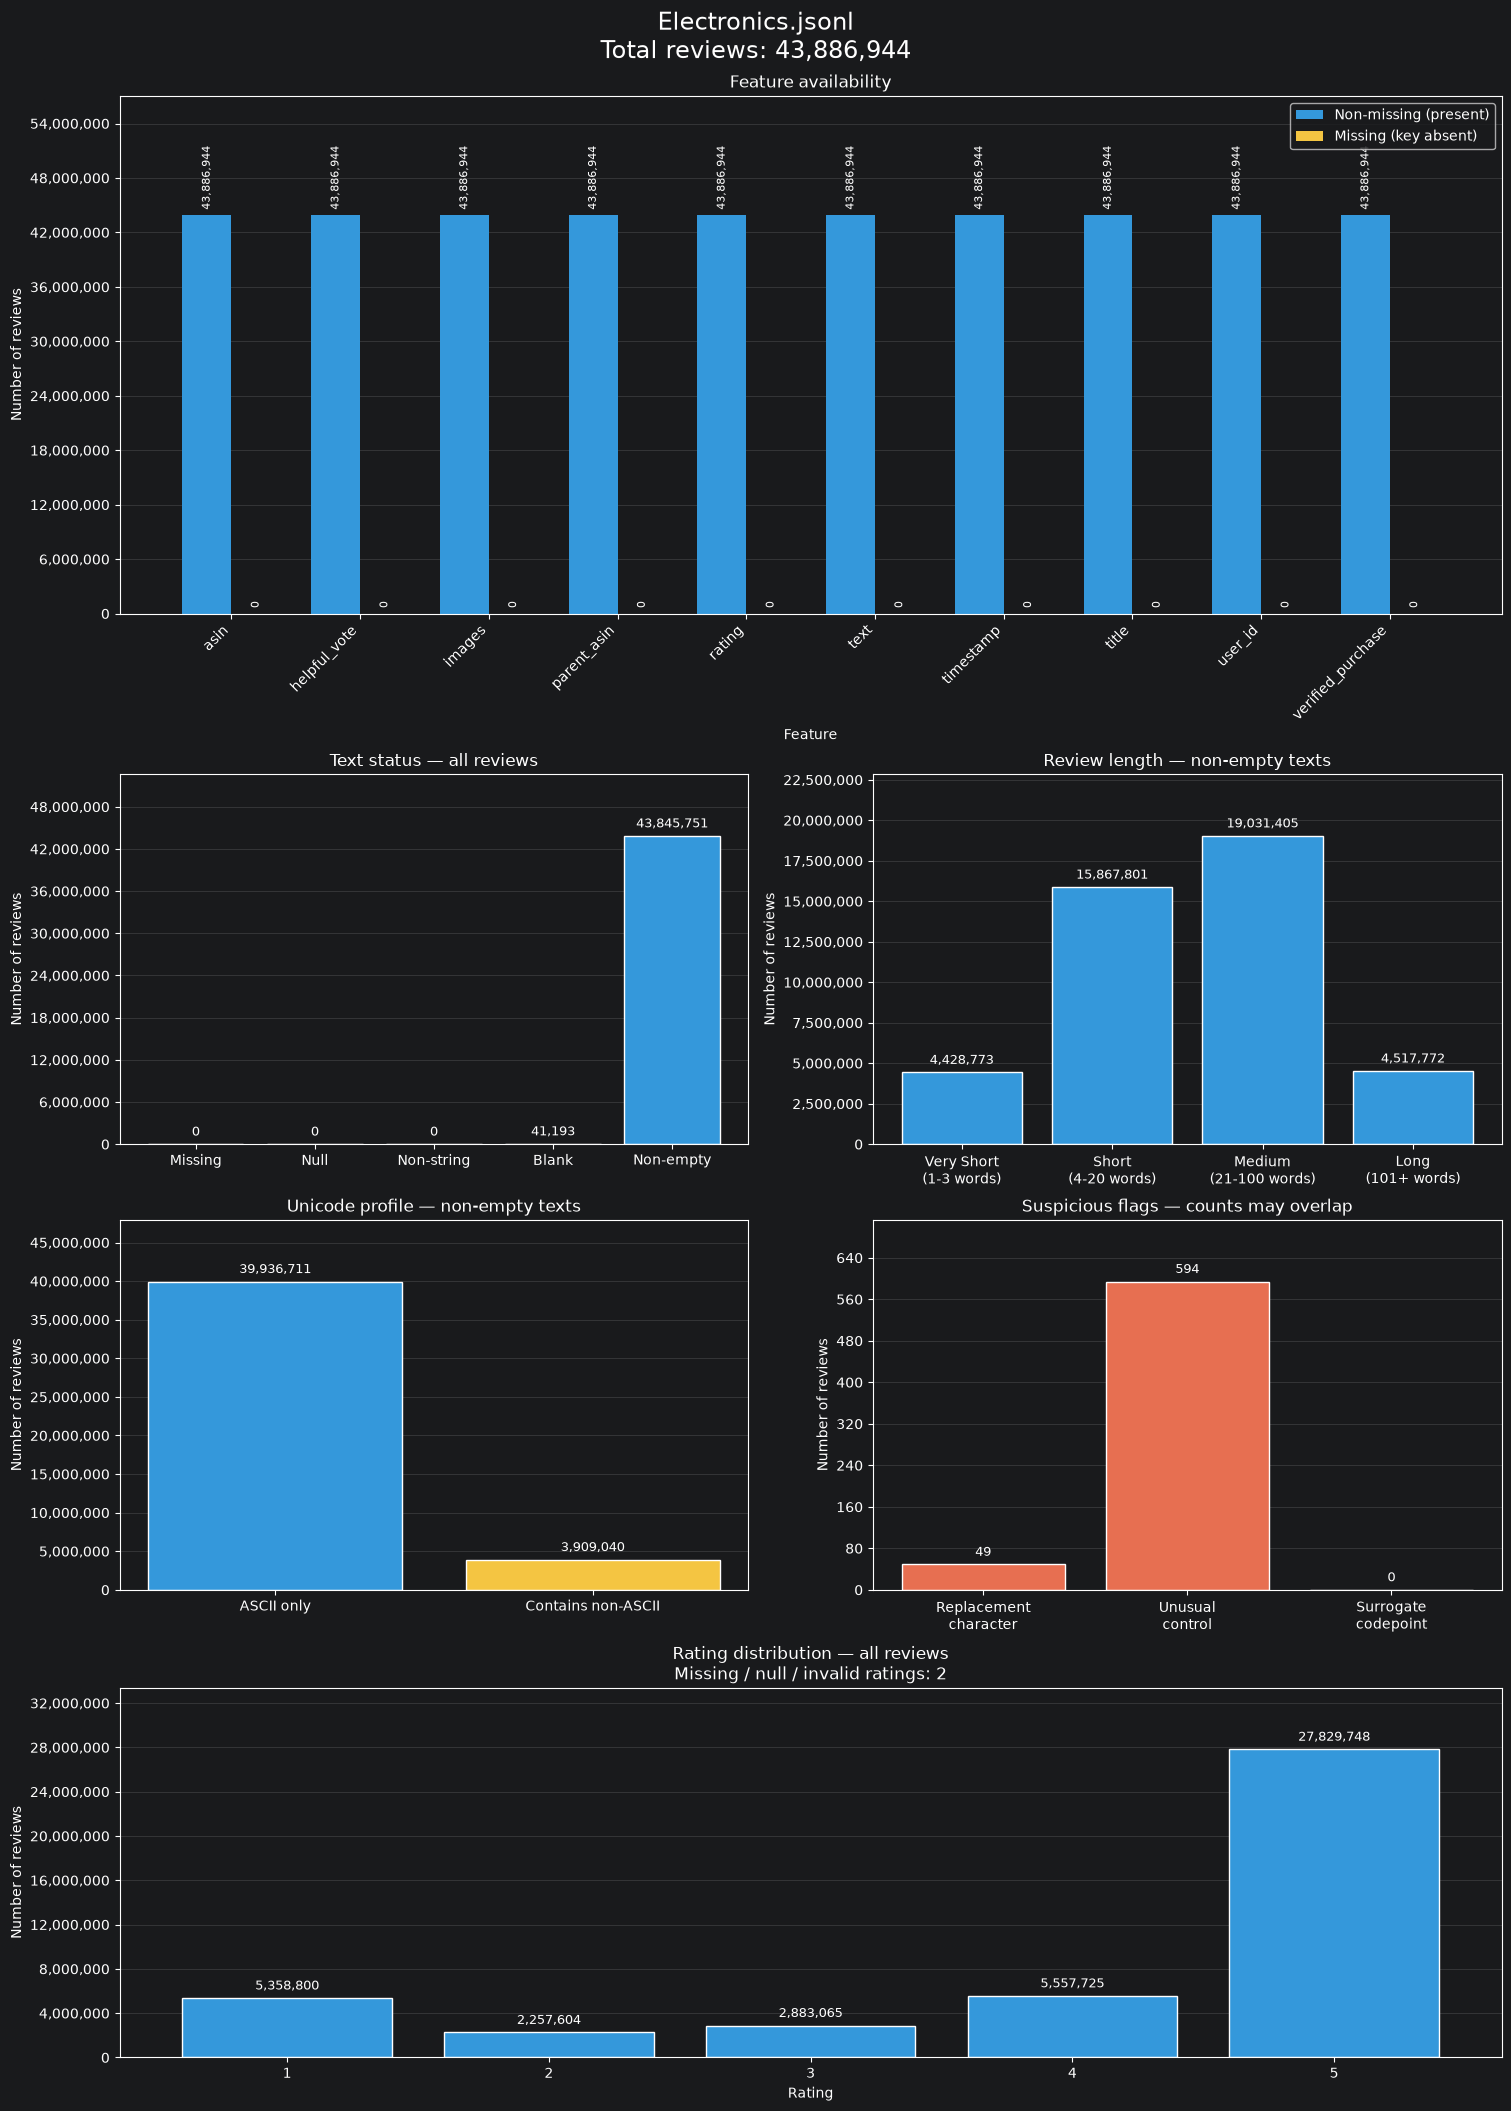

In [6]:
plot_review_report("Electronics.jsonl")